In [2]:
import yfinance as yf
import pandas as pd

# Step 1: Define Bitcoin download settings
ticker = "BTC-USD"
period = "6mo"
interval = "1h"

# Step 2: Download historical data
df = yf.download(
    ticker,
    period=period,
    interval=interval,
    auto_adjust=False,
    progress=False
)

# Step 3: Check whether data was downloaded
if df.empty:
    print("No data downloaded. Check your internet connection or try again.")

else:
    # Step 4: Handle MultiIndex columns
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    # Step 5: Reset index
    df = df.reset_index()

    # Step 6: Standardize timestamp column
    if "Datetime" not in df.columns and "Date" in df.columns:
        df = df.rename(columns={"Date": "Datetime"})

    # Step 7: Keep required columns
    required_columns = [
        "Datetime", "Open", "High",
        "Low", "Close", "Volume"
    ]

    df = df[[col for col in required_columns if col in df.columns]]

    # Step 8: Clean and sort data
    df = df.drop_duplicates(subset=["Datetime"])
    df = df.sort_values("Datetime").reset_index(drop=True)

    # Step 9: Save only as CSV in the current Jupyter folder
    csv_file = "Bitcoin_6Month_1Hour_Data.csv"
    df.to_csv(csv_file, index=False)

    # Step 10: Verify results
    print("Bitcoin 1-hour data downloaded successfully!")
    print("Dataset shape:", df.shape)

    print("\nFirst 5 rows:")
    print(df.head())

    print("\nLast 5 rows:")
    print(df.tail())

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDate range:")
    print(df["Datetime"].min(), "to", df["Datetime"].max())

    print("\nCSV file saved:", csv_file)
    print("Jupyter folder:", __import__("os").getcwd())


Bitcoin 1-hour data downloaded successfully!
Dataset shape: (4392, 6)

First 5 rows:
Price                  Datetime          Open          High           Low  \
0     2026-04-16 09:00:00+00:00  74679.250000  74927.828125  74611.796875   
1     2026-04-16 10:00:00+00:00  74611.882812  74670.843750  74290.781250   
2     2026-04-16 11:00:00+00:00  74327.992188  74601.656250  74300.007812   
3     2026-04-16 12:00:00+00:00  74593.328125  74876.343750  74592.906250   
4     2026-04-16 13:00:00+00:00  74628.789062  75023.179688  73309.726562   

Price         Close     Volume  
0      74612.671875          0  
1      74323.992188          0  
2      74593.328125  396546048  
3      74632.867188          0  
4      73793.976562  937250816  

Last 5 rows:
Price                  Datetime          Open          High           Low  \
4387  2026-10-16 05:00:00+00:00  82077.820312  82312.093750  81946.148438   
4388  2026-10-16 06:00:00+00:00  82055.500000  82200.000000  81907.562500   
4389  202

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load Bitcoin 6-month, 1-hour dataset
file_path = "Bitcoin_6Month_1Hour_Data.csv"

df = pd.read_csv(file_path)

# Convert timestamp column to datetime
df["Datetime"] = pd.to_datetime(df["Datetime"])

# Sort data chronologically
df = df.sort_values("Datetime").reset_index(drop=True)

# Verify the dataset
print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df[["Open", "High", "Low", "Close"]].isnull().sum())

print("\nDate range:")
print(df["Datetime"].min(), "to", df["Datetime"].max())


Dataset loaded successfully!
Shape: (4392, 6)

First 5 rows:
                   Datetime          Open          High           Low  \
0 2026-04-16 09:00:00+00:00  74679.250000  74927.828125  74611.796875   
1 2026-04-16 10:00:00+00:00  74611.882812  74670.843750  74290.781250   
2 2026-04-16 11:00:00+00:00  74327.992188  74601.656250  74300.007812   
3 2026-04-16 12:00:00+00:00  74593.328125  74876.343750  74592.906250   
4 2026-04-16 13:00:00+00:00  74628.789062  75023.179688  73309.726562   

          Close     Volume  
0  74612.671875          0  
1  74323.992188          0  
2  74593.328125  396546048  
3  74632.867188          0  
4  73793.976562  937250816  

Columns:
['Datetime', 'Open', 'High', 'Low', 'Close', 'Volume']

Missing values:
Open     0
High     0
Low      0
Close    0
dtype: int64

Date range:
2026-04-16 09:00:00+00:00 to 2026-10-16 09:00:00+00:00


In [4]:
df["EMA_9"] = df["Close"].ewm(
    span=9,
    adjust=False
).mean()

df["EMA_12"] = df["Close"].ewm(
    span=12,
    adjust=False
).mean()

# Display results
print("EMA 9 and EMA 12 calculated successfully!")

print("\nLatest 10 rows:")
print(df[["Datetime", "Close", "EMA_9", "EMA_12"]].tail(10))

# Check missing values in EMA columns
print("\nMissing EMA values:")
print(df[["EMA_9", "EMA_12"]].isnull().sum())


EMA 9 and EMA 12 calculated successfully!

Latest 10 rows:
                      Datetime         Close         EMA_9        EMA_12
4382 2026-10-16 00:00:00+00:00  82231.468750  82103.065843  82015.741052
4383 2026-10-16 01:00:00+00:00  81974.820312  82077.416737  82009.445553
4384 2026-10-16 02:00:00+00:00  81935.757812  82049.084952  81998.108978
4385 2026-10-16 03:00:00+00:00  82008.156250  82040.899212  81999.654712
4386 2026-10-16 04:00:00+00:00  82052.117188  82043.142807  82007.725862
4387 2026-10-16 05:00:00+00:00  82052.156250  82044.945495  82014.561306
4388 2026-10-16 06:00:00+00:00  82079.242188  82051.804834  82024.512211
4389 2026-10-16 07:00:00+00:00  82186.203125  82078.684492  82049.387736
4390 2026-10-16 08:00:00+00:00  82139.320312  82090.811656  82063.223517
4391 2026-10-16 09:00:00+00:00  82058.296875  82084.308700  82062.465572

Missing EMA values:
EMA_9     0
EMA_12    0
dtype: int64


In [7]:
%pip install mplfinance

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


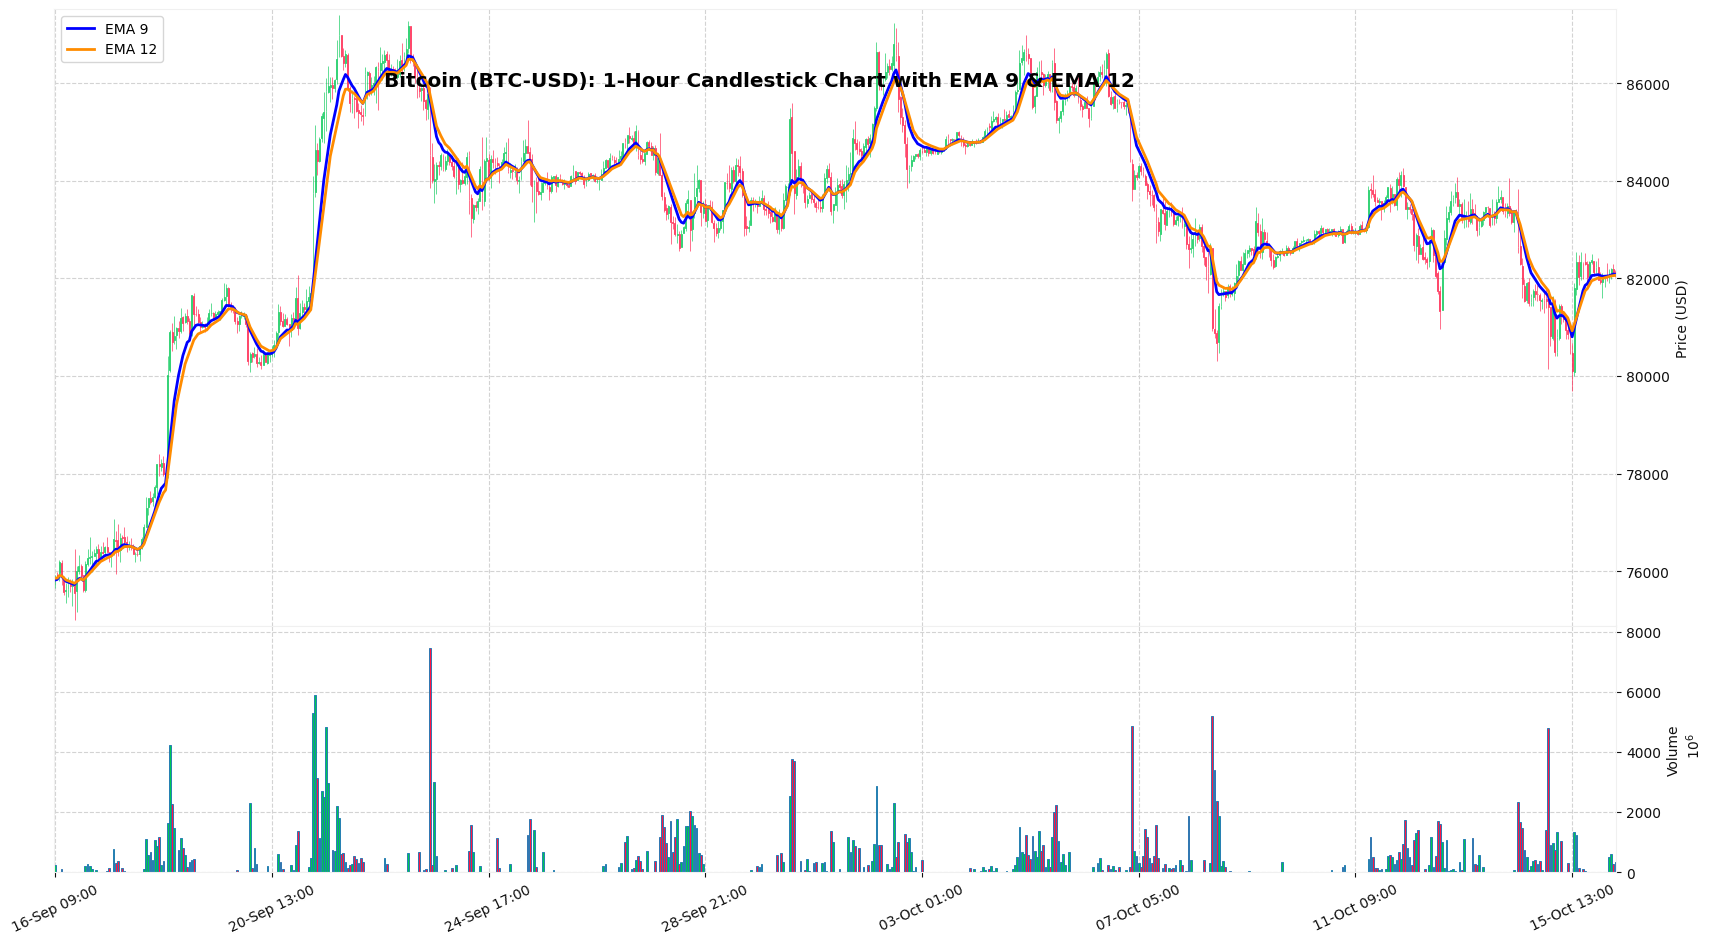

Candlestick chart plotted successfully.
Candles displayed: 721
Chart period: 2026-09-16 09:00:00+00:00 to 2026-10-16 09:00:00+00:00
EMA 9 and EMA 12 calculated using Close prices only.


In [8]:
import pandas as pd
import mplfinance as mpf
import matplotlib.pyplot as plt

# Load Bitcoin data
df = pd.read_csv("Bitcoin_6Month_1Hour_Data.csv")

# Prepare and clean the data
df["Datetime"] = pd.to_datetime(df["Datetime"], utc=True)

numeric_columns = ["Open", "High", "Low", "Close", "Volume"]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Datetime"] + numeric_columns)
df = df.drop_duplicates(subset=["Datetime"])
df = df.sort_values("Datetime").reset_index(drop=True)

# Calculate EMA using Close prices only
df["EMA_9"] = df["Close"].ewm(span=9, adjust=False).mean()
df["EMA_12"] = df["Close"].ewm(span=12, adjust=False).mean()

# Set Datetime as the chart index
df = df.set_index("Datetime").sort_index()

# Plot the most recent 30 days for better visibility
chart_df = df.loc[
    df.index >= df.index.max() - pd.Timedelta(days=30)
].copy()

if chart_df.empty:
    raise ValueError("No data available for plotting.")

# Define green bullish and red bearish candles
market_colors = mpf.make_marketcolors(
    up="#00C853",
    down="#FF1744",
    edge={"up": "#00C853", "down": "#FF1744"},
    wick={"up": "#00C853", "down": "#FF1744"},
    volume={"up": "#00C853", "down": "#FF1744"}
)

chart_style = mpf.make_mpf_style(
    base_mpf_style="yahoo",
    marketcolors=market_colors,
    gridstyle="--",
    gridcolor="lightgray",
    facecolor="white",
    figcolor="white"
)

# Add visible EMA lines
ema9_plot = mpf.make_addplot(
    chart_df["EMA_9"],
    color="blue",
    width=2.0
)

ema12_plot = mpf.make_addplot(
    chart_df["EMA_12"],
    color="darkorange",
    width=2.0
)

# Plot candlesticks, EMAs and volume
fig, axes = mpf.plot(
    chart_df[["Open", "High", "Low", "Close", "Volume"]],
    type="candle",
    style=chart_style,
    addplot=[ema9_plot, ema12_plot],
    title="Bitcoin (BTC-USD): 1-Hour Candlestick Chart with EMA 9 & EMA 12",
    ylabel="Price (USD)",
    ylabel_lower="Volume",
    volume=True,
    figsize=(18, 10),
    datetime_format="%d-%b %H:%M",
    xrotation=25,
    tight_layout=True,
    returnfig=True,
    warn_too_much_data=len(chart_df) + 100
)

# Add a clear EMA legend
axes[0].plot([], [], color="blue", linewidth=2, label="EMA 9")
axes[0].plot([], [], color="darkorange", linewidth=2, label="EMA 12")
axes[0].legend(loc="upper left", fontsize=10)

plt.show()

# Display chart information
print("Candlestick chart plotted successfully.")
print("Candles displayed:", len(chart_df))
print("Chart period:", chart_df.index.min(), "to", chart_df.index.max())
print("EMA 9 and EMA 12 calculated using Close prices only.")


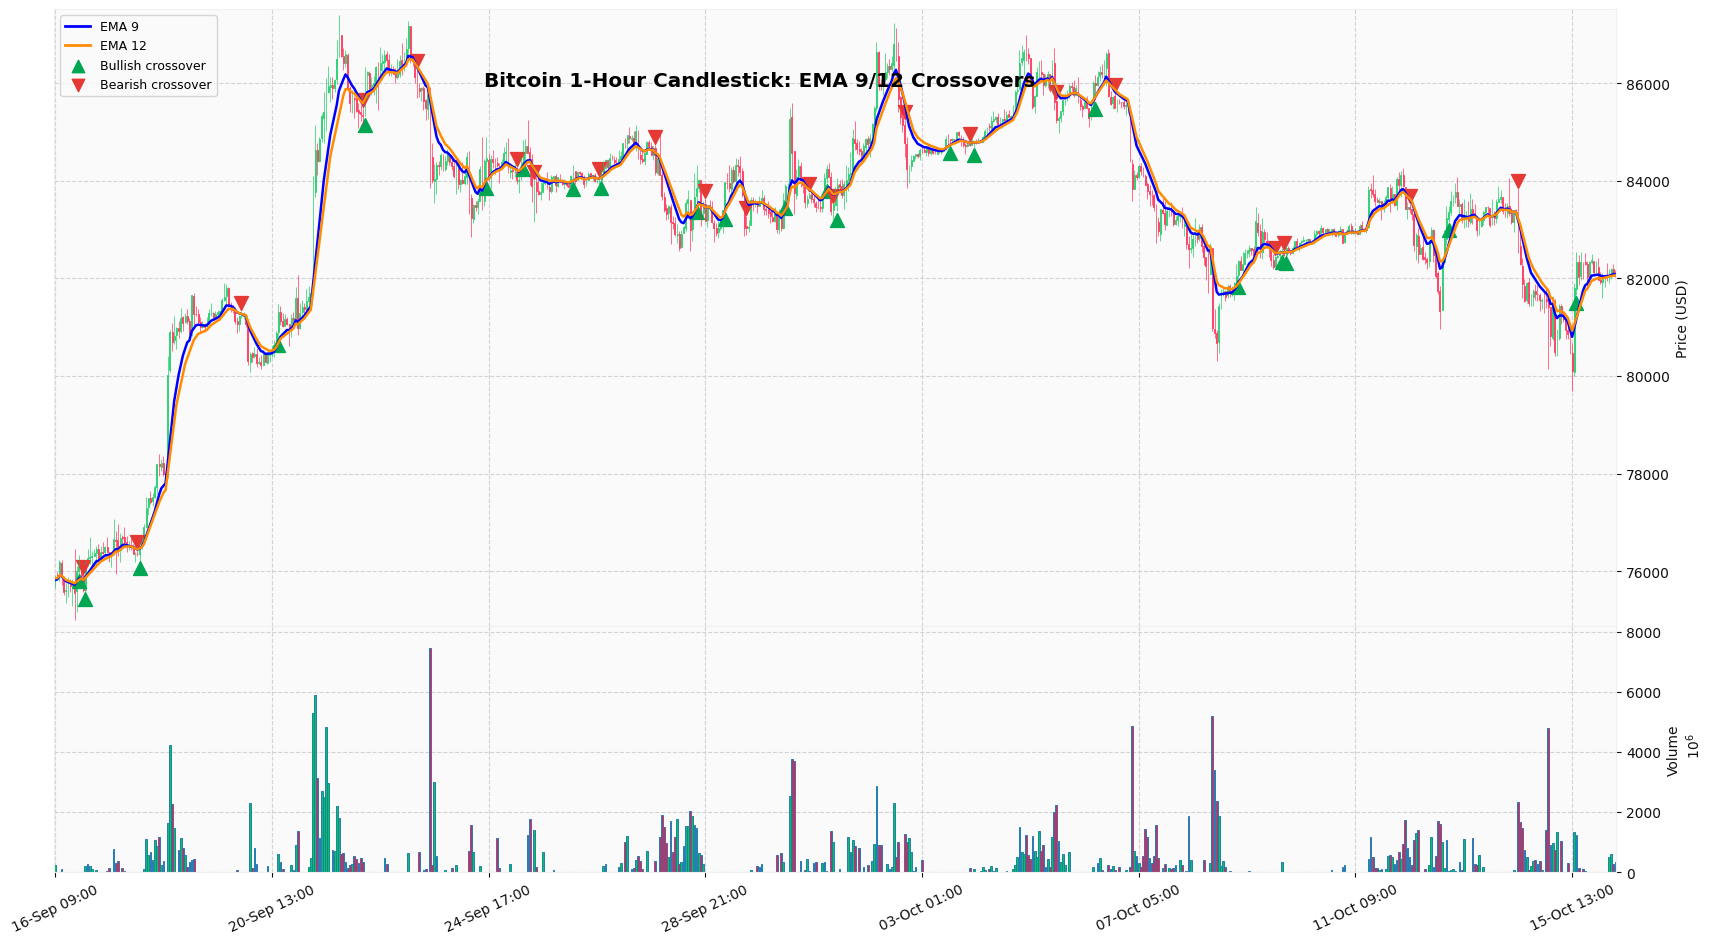

Total bullish crossovers: 131
Total bearish crossovers: 131

Crossovers in the displayed 30-day chart:
                                  Close         EMA_9        EMA_12  \
Datetime                                                              
2026-09-30 21:00:00+00:00  83712.593750  83831.352305  83832.917720   
2026-10-01 05:00:00+00:00  84252.007812  83815.229804  83794.075410   
2026-10-01 08:00:00+00:00  83519.460938  83718.545847  83727.944411   
2026-10-01 10:00:00+00:00  83922.062500  83763.398092  83759.960847   
2026-10-02 17:00:00+00:00  84776.093750  85608.985047  85648.682638   
2026-10-03 14:00:00+00:00  84843.000000  84735.747342  84729.991374   
2026-10-03 23:00:00+00:00  84742.218750  84780.959932  84781.743590   
2026-10-04 01:00:00+00:00  84794.703125  84784.589981  84784.352474   
2026-10-05 15:00:00+00:00  85251.546875  85872.948081  85905.888978   
2026-10-06 09:00:00+00:00  85970.671875  85708.833632  85701.475082   
2026-10-06 18:00:00+00:00  85494.007812  8582

In [9]:
import pandas as pd
import mplfinance as mpf
import matplotlib.pyplot as plt

df = pd.read_csv("Bitcoin_6Month_1Hour_Data.csv")

df["Datetime"] = pd.to_datetime(df["Datetime"], utc=True)

for col in ["Open", "High", "Low", "Close", "Volume"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = (
    df.dropna(subset=["Datetime", "Open", "High", "Low", "Close"])
      .drop_duplicates(subset=["Datetime"])
      .sort_values("Datetime")
      .reset_index(drop=True)
)

# Calculate EMA from Close prices only
df["EMA_9"] = df["Close"].ewm(span=9, adjust=False).mean()
df["EMA_12"] = df["Close"].ewm(span=12, adjust=False).mean()

# Detect crossover events
df["EMA_Difference"] = df["EMA_9"] - df["EMA_12"]
df["Previous_Difference"] = df["EMA_Difference"].shift(1)

df["Bullish_Crossover"] = (
    (df["Previous_Difference"] <= 0) &
    (df["EMA_Difference"] > 0)
)

df["Bearish_Crossover"] = (
    (df["Previous_Difference"] >= 0) &
    (df["EMA_Difference"] < 0)
)

# Prepare chart data
df = df.set_index("Datetime").sort_index()

# Show the latest 30 days for better visibility
chart_df = df.loc[
    df.index >= df.index.max() - pd.Timedelta(days=30)
].copy()

# Place markers slightly above/below candle prices
chart_df["Bullish_Marker"] = float("nan")
chart_df["Bearish_Marker"] = float("nan")

chart_df.loc[
    chart_df["Bullish_Crossover"], "Bullish_Marker"
] = chart_df.loc[
    chart_df["Bullish_Crossover"], "Low"
] * 0.998

chart_df.loc[
    chart_df["Bearish_Crossover"], "Bearish_Marker"
] = chart_df.loc[
    chart_df["Bearish_Crossover"], "High"
] * 1.002

# Chart colors
market_colors = mpf.make_marketcolors(
    up="#00C853",
    down="#FF1744",
    edge={"up": "#00C853", "down": "#FF1744"},
    wick={"up": "#00C853", "down": "#FF1744"},
    volume={"up": "#00C853", "down": "#FF1744"}
)

chart_style = mpf.make_mpf_style(
    base_mpf_style="yahoo",
    marketcolors=market_colors,
    gridstyle="--",
    gridcolor="lightgray"
)

addplots = [
    mpf.make_addplot(
        chart_df["EMA_9"],
        color="blue",
        width=1.8
    ),
    mpf.make_addplot(
        chart_df["EMA_12"],
        color="darkorange",
        width=1.8
    )
]

if chart_df["Bullish_Marker"].notna().any():
    addplots.append(
        mpf.make_addplot(
            chart_df["Bullish_Marker"],
            type="scatter",
            marker="^",
            color="#00A651",
            markersize=100
        )
    )

if chart_df["Bearish_Marker"].notna().any():
    addplots.append(
        mpf.make_addplot(
            chart_df["Bearish_Marker"],
            type="scatter",
            marker="v",
            color="#E53935",
            markersize=100
        )
    )

fig, axes = mpf.plot(
    chart_df[["Open", "High", "Low", "Close", "Volume"]],
    type="candle",
    style=chart_style,
    addplot=addplots,
    title="Bitcoin 1-Hour Candlestick: EMA 9/12 Crossovers",
    ylabel="Price (USD)",
    ylabel_lower="Volume",
    volume=True,
    figsize=(18, 10),
    datetime_format="%d-%b %H:%M",
    xrotation=25,
    tight_layout=True,
    returnfig=True,
    warn_too_much_data=len(chart_df) + 100
)

axes[0].plot([], [], color="blue", linewidth=2, label="EMA 9")
axes[0].plot([], [], color="darkorange", linewidth=2, label="EMA 12")
axes[0].scatter([], [], marker="^", color="#00A651",
                s=80, label="Bullish crossover")
axes[0].scatter([], [], marker="v", color="#E53935",
                s=80, label="Bearish crossover")
axes[0].legend(loc="upper left", fontsize=9)

plt.show()

# Display crossover results
crossovers = df.loc[
    df["Bullish_Crossover"] | df["Bearish_Crossover"],
    ["Close", "EMA_9", "EMA_12", "Bullish_Crossover", "Bearish_Crossover"]
].copy()

crossovers["Signal"] = crossovers["Bullish_Crossover"].map(
    {True: "Bullish", False: ""}
)
crossovers.loc[crossovers["Bearish_Crossover"], "Signal"] = "Bearish"

print("Total bullish crossovers:", int(df["Bullish_Crossover"].sum()))
print("Total bearish crossovers:", int(df["Bearish_Crossover"].sum()))

print("\nCrossovers in the displayed 30-day chart:")
print(crossovers.loc[crossovers.index.isin(chart_df.index)].tail(20))

print("\nAll crossover events from the full dataset:")
print(crossovers.tail(20))


In [10]:
%pip install plotly


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


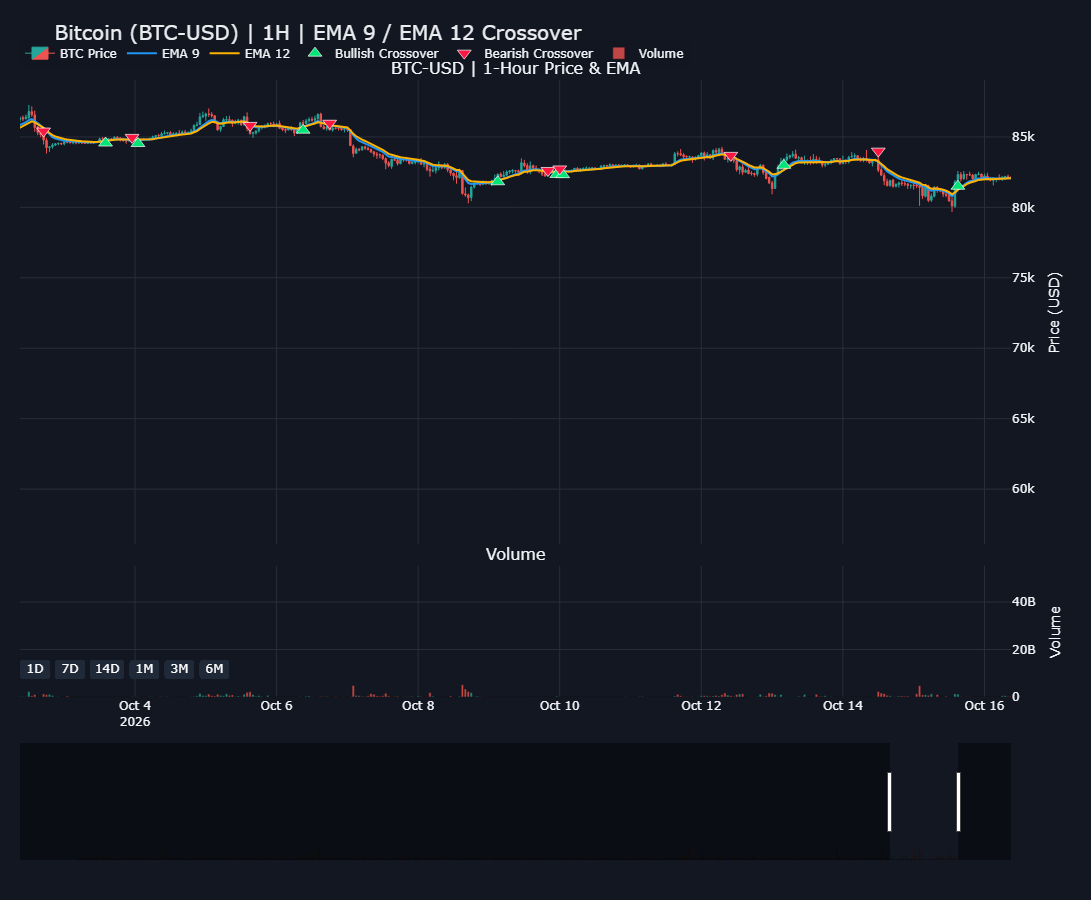

Interactive chart created.
Dataset rows: 4392
Bullish crossovers: 131
Bearish crossovers: 131
Full data range: 2026-04-16 09:00:00+00:00 to 2026-10-16 09:00:00+00:00


In [11]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Load the original Bitcoin dataset
df = pd.read_csv("Bitcoin_6Month_1Hour_Data.csv")

df["Datetime"] = pd.to_datetime(df["Datetime"], utc=True)

for col in ["Open", "High", "Low", "Close", "Volume"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = (
    df.dropna(subset=["Datetime", "Open", "High", "Low", "Close"])
      .drop_duplicates(subset=["Datetime"])
      .sort_values("Datetime")
      .reset_index(drop=True)
)

# Calculate EMAs using Close prices only
df["EMA_9"] = df["Close"].ewm(span=9, adjust=False).mean()
df["EMA_12"] = df["Close"].ewm(span=12, adjust=False).mean()

# Detect bullish and bearish crossovers
difference = df["EMA_9"] - df["EMA_12"]
previous_difference = difference.shift(1)

df["Bullish_Crossover"] = (
    (previous_difference <= 0) & (difference > 0)
)

df["Bearish_Crossover"] = (
    (previous_difference >= 0) & (difference < 0)
)

# Create crossover data
bullish = df[df["Bullish_Crossover"]].copy()
bearish = df[df["Bearish_Crossover"]].copy()

# Create separate price and volume panels
fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.035,
    row_heights=[0.78, 0.22],
    subplot_titles=("BTC-USD | 1-Hour Price & EMA", "Volume")
)

# Candlesticks
fig.add_trace(
    go.Candlestick(
        x=df["Datetime"],
        open=df["Open"],
        high=df["High"],
        low=df["Low"],
        close=df["Close"],
        name="BTC Price",
        increasing=dict(
            line=dict(color="#26A69A", width=1),
            fillcolor="#26A69A"
        ),
        decreasing=dict(
            line=dict(color="#EF5350", width=1),
            fillcolor="#EF5350"
        ),
        whiskerwidth=0.5,
        hoverlabel=dict(
            bgcolor="#202938",
            font=dict(color="white")
        )
    ),
    row=1,
    col=1
)

# EMA 9
fig.add_trace(
    go.Scatter(
        x=df["Datetime"],
        y=df["EMA_9"],
        mode="lines",
        name="EMA 9",
        line=dict(color="#2196F3", width=2),
        hovertemplate="EMA 9: $%{y:,.2f}<extra></extra>"
    ),
    row=1,
    col=1
)

# EMA 12
fig.add_trace(
    go.Scatter(
        x=df["Datetime"],
        y=df["EMA_12"],
        mode="lines",
        name="EMA 12",
        line=dict(color="#FFB300", width=2),
        hovertemplate="EMA 12: $%{y:,.2f}<extra></extra>"
    ),
    row=1,
    col=1
)

# Bullish crossover markers
fig.add_trace(
    go.Scatter(
        x=bullish["Datetime"],
        y=bullish["Low"] * 0.998,
        mode="markers",
        name="Bullish Crossover",
        marker=dict(
            symbol="triangle-up",
            size=12,
            color="#00E676",
            line=dict(color="white", width=0.7)
        ),
        customdata=bullish[["Close", "EMA_9", "EMA_12"]].to_numpy(),
        hovertemplate=(
            "<b>BULLISH CROSSOVER</b><br>"
            "Time: %{x|%d %b %Y %H:%M UTC}<br>"
            "Close: $%{customdata[0]:,.2f}<br>"
            "EMA 9: $%{customdata[1]:,.2f}<br>"
            "EMA 12: $%{customdata[2]:,.2f}"
            "<extra></extra>"
        )
    ),
    row=1,
    col=1
)

# Bearish crossover markers
fig.add_trace(
    go.Scatter(
        x=bearish["Datetime"],
        y=bearish["High"] * 1.002,
        mode="markers",
        name="Bearish Crossover",
        marker=dict(
            symbol="triangle-down",
            size=12,
            color="#FF1744",
            line=dict(color="white", width=0.7)
        ),
        customdata=bearish[["Close", "EMA_9", "EMA_12"]].to_numpy(),
        hovertemplate=(
            "<b>BEARISH CROSSOVER</b><br>"
            "Time: %{x|%d %b %Y %H:%M UTC}<br>"
            "Close: $%{customdata[0]:,.2f}<br>"
            "EMA 9: $%{customdata[1]:,.2f}<br>"
            "EMA 12: $%{customdata[2]:,.2f}"
            "<extra></extra>"
        )
    ),
    row=1,
    col=1
)

# Volume bars colored according to price direction
volume_colors = [
    "#26A69A" if close >= open_price else "#EF5350"
    for open_price, close in zip(df["Open"], df["Close"])
]

fig.add_trace(
    go.Bar(
        x=df["Datetime"],
        y=df["Volume"],
        name="Volume",
        marker_color=volume_colors,
        opacity=0.8,
        hovertemplate="Volume: %{y:,.0f}<extra></extra>"
    ),
    row=2,
    col=1
)

# Trading-style dark layout
fig.update_layout(
    title=dict(
        text="Bitcoin (BTC-USD) | 1H | EMA 9 / EMA 12 Crossover",
        font=dict(size=20, color="#EAECEF")
    ),
    template="plotly_dark",
    paper_bgcolor="#131722",
    plot_bgcolor="#131722",
    height=900,
    hovermode="x unified",
    dragmode="zoom",
    margin=dict(l=20, r=80, t=80, b=40),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0,
        bgcolor="rgba(19,23,34,0.8)"
    ),
    xaxis_rangeslider_visible=False,
    showlegend=True
)

# Price and volume axis formatting
fig.update_yaxes(
    title_text="Price (USD)",
    side="right",
    showgrid=True,
    gridcolor="#2A2E39",
    zeroline=False,
    row=1,
    col=1
)

fig.update_yaxes(
    title_text="Volume",
    side="right",
    showgrid=True,
    gridcolor="#2A2E39",
    zeroline=False,
    row=2,
    col=1
)

fig.update_xaxes(
    showgrid=True,
    gridcolor="#2A2E39",
    rangeslider_visible=False,
    row=1,
    col=1
)

fig.update_xaxes(
    showgrid=True,
    gridcolor="#2A2E39",
    rangeslider_visible=True,
    rangeselector=dict(
        buttons=[
            dict(count=1, label="1D", step="day", stepmode="backward"),
            dict(count=7, label="7D", step="day", stepmode="backward"),
            dict(count=14, label="14D", step="day", stepmode="backward"),
            dict(count=1, label="1M", step="month", stepmode="backward"),
            dict(count=3, label="3M", step="month", stepmode="backward"),
            dict(step="all", label="6M")
        ],
        bgcolor="#202938",
        activecolor="#2962FF",
        font=dict(color="white")
    ),
    row=2,
    col=1
)

# Initially display the latest 14 days for detail
latest_time = df["Datetime"].max()
initial_start = latest_time - pd.Timedelta(days=14)

fig.update_xaxes(
    range=[initial_start, latest_time],
    row=1,
    col=1
)

fig.update_xaxes(
    range=[initial_start, latest_time],
    row=2,
    col=1
)

fig.show()

print("Interactive chart created.")
print("Dataset rows:", len(df))
print("Bullish crossovers:", len(bullish))
print("Bearish crossovers:", len(bearish))
print("Full data range:", df["Datetime"].min(), "to", df["Datetime"].max())


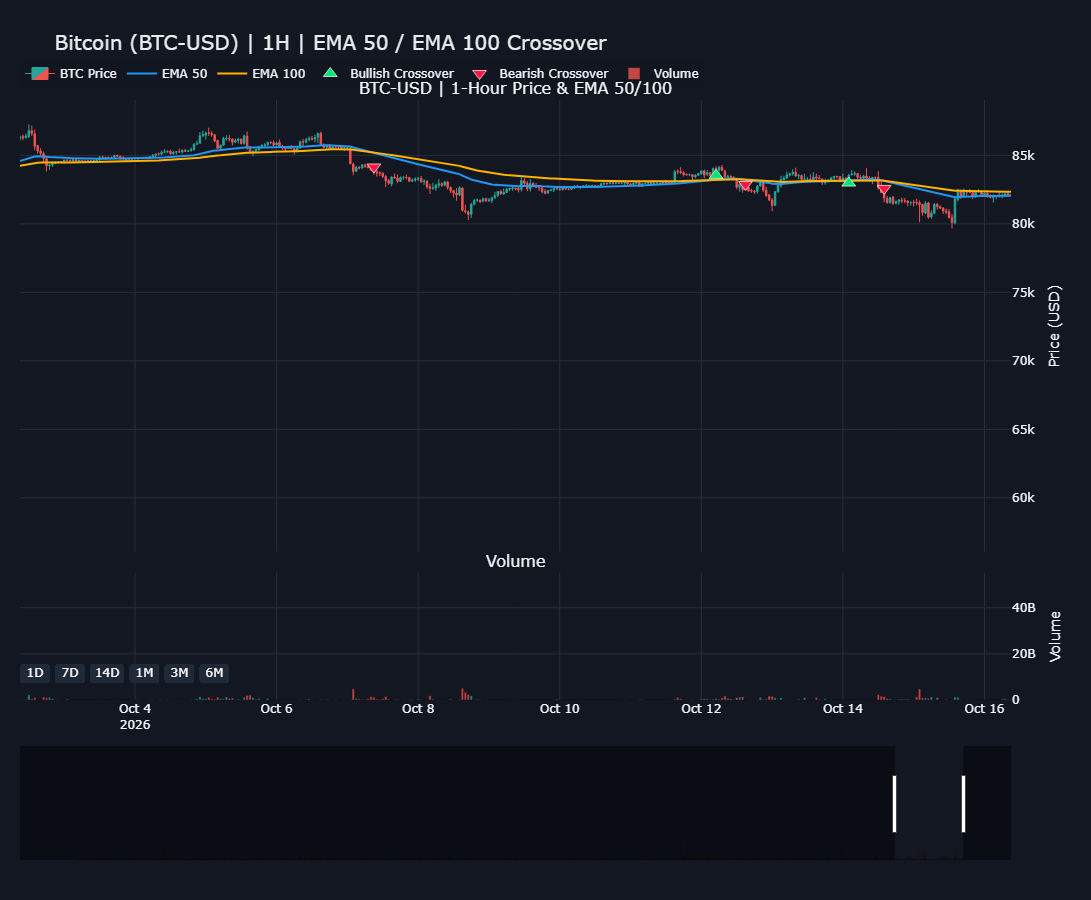

Interactive chart created successfully.
Dataset rows: 4392
Bullish crossovers: 23
Bearish crossovers: 24
Full data range: 2026-04-16 09:00:00+00:00 to 2026-10-16 09:00:00+00:00


In [12]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

df = pd.read_csv("Bitcoin_6Month_1Hour_Data.csv")

df["Datetime"] = pd.to_datetime(df["Datetime"], utc=True)

for col in ["Open", "High", "Low", "Close", "Volume"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = (
    df.dropna(subset=["Datetime", "Open", "High", "Low", "Close"])
      .drop_duplicates(subset=["Datetime"])
      .sort_values("Datetime")
      .reset_index(drop=True)
)

df["EMA_50"] = df["Close"].ewm(span=50, adjust=False).mean()
df["EMA_100"] = df["Close"].ewm(span=100, adjust=False).mean()

difference = df["EMA_50"] - df["EMA_100"]
previous_difference = difference.shift(1)

df["Bullish_Crossover"] = (
    (previous_difference <= 0) & (difference > 0)
)

df["Bearish_Crossover"] = (
    (previous_difference >= 0) & (difference < 0)
)

bullish = df[df["Bullish_Crossover"]].copy()
bearish = df[df["Bearish_Crossover"]].copy()

fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.035,
    row_heights=[0.78, 0.22],
    subplot_titles=("BTC-USD | 1-Hour Price & EMA 50/100", "Volume")
)

fig.add_trace(
    go.Candlestick(
        x=df["Datetime"],
        open=df["Open"],
        high=df["High"],
        low=df["Low"],
        close=df["Close"],
        name="BTC Price",
        increasing=dict(line=dict(color="#26A69A", width=1),
                       fillcolor="#26A69A"),
        decreasing=dict(line=dict(color="#EF5350", width=1),
                       fillcolor="#EF5350"),
        whiskerwidth=0.5
    ),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(
        x=df["Datetime"],
        y=df["EMA_50"],
        mode="lines",
        name="EMA 50",
        line=dict(color="#2196F3", width=2),
        hovertemplate="EMA 50: $%{y:,.2f}<extra></extra>"
    ),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(
        x=df["Datetime"],
        y=df["EMA_100"],
        mode="lines",
        name="EMA 100",
        line=dict(color="#FFB300", width=2),
        hovertemplate="EMA 100: $%{y:,.2f}<extra></extra>"
    ),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(
        x=bullish["Datetime"],
        y=bullish["Low"] * 0.998,
        mode="markers",
        name="Bullish Crossover",
        marker=dict(
            symbol="triangle-up",
            size=12,
            color="#00E676",
            line=dict(color="white", width=0.7)
        ),
        customdata=bullish[["Close", "EMA_50", "EMA_100"]].to_numpy(),
        hovertemplate=(
            "<b>BULLISH CROSSOVER</b><br>"
            "Time: %{x|%d %b %Y %H:%M UTC}<br>"
            "Close: $%{customdata[0]:,.2f}<br>"
            "EMA 50: $%{customdata[1]:,.2f}<br>"
            "EMA 100: $%{customdata[2]:,.2f}"
            "<extra></extra>"
        )
    ),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(
        x=bearish["Datetime"],
        y=bearish["High"] * 1.002,
        mode="markers",
        name="Bearish Crossover",
        marker=dict(
            symbol="triangle-down",
            size=12,
            color="#FF1744",
            line=dict(color="white", width=0.7)
        ),
        customdata=bearish[["Close", "EMA_50", "EMA_100"]].to_numpy(),
        hovertemplate=(
            "<b>BEARISH CROSSOVER</b><br>"
            "Time: %{x|%d %b %Y %H:%M UTC}<br>"
            "Close: $%{customdata[0]:,.2f}<br>"
            "EMA 50: $%{customdata[1]:,.2f}<br>"
            "EMA 100: $%{customdata[2]:,.2f}"
            "<extra></extra>"
        )
    ),
    row=1, col=1
)

volume_colors = [
    "#26A69A" if close >= open_price else "#EF5350"
    for open_price, close in zip(df["Open"], df["Close"])
]

fig.add_trace(
    go.Bar(
        x=df["Datetime"],
        y=df["Volume"],
        name="Volume",
        marker_color=volume_colors,
        opacity=0.8,
        hovertemplate="Volume: %{y:,.0f}<extra></extra>"
    ),
    row=2, col=1
)

fig.update_layout(
    title=dict(
        text="Bitcoin (BTC-USD) | 1H | EMA 50 / EMA 100 Crossover",
        font=dict(size=20, color="#EAECEF")
    ),
    template="plotly_dark",
    paper_bgcolor="#131722",
    plot_bgcolor="#131722",
    height=900,
    hovermode="x unified",
    dragmode="zoom",
    margin=dict(l=20, r=80, t=100, b=40),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0,
        bgcolor="rgba(19,23,34,0.8)"
    )
)

fig.update_yaxes(
    title_text="Price (USD)",
    side="right",
    showgrid=True,
    gridcolor="#2A2E39",
    zeroline=False,
    row=1, col=1
)

fig.update_yaxes(
    title_text="Volume",
    side="right",
    showgrid=True,
    gridcolor="#2A2E39",
    zeroline=False,
    row=2, col=1
)

fig.update_xaxes(
    showgrid=True,
    gridcolor="#2A2E39",
    rangeslider_visible=False,
    row=1, col=1
)

fig.update_xaxes(
    showgrid=True,
    gridcolor="#2A2E39",
    rangeslider_visible=True,
    rangeselector=dict(
        buttons=[
            dict(count=1, label="1D", step="day", stepmode="backward"),
            dict(count=7, label="7D", step="day", stepmode="backward"),
            dict(count=14, label="14D", step="day", stepmode="backward"),
            dict(count=1, label="1M", step="month", stepmode="backward"),
            dict(count=3, label="3M", step="month", stepmode="backward"),
            dict(step="all", label="6M")
        ],
        bgcolor="#202938",
        activecolor="#2962FF",
        font=dict(color="white")
    ),
    row=2, col=1
)

latest_time = df["Datetime"].max()
initial_start = latest_time - pd.Timedelta(days=14)

fig.update_xaxes(
    range=[initial_start, latest_time],
    row=1, col=1
)

fig.update_xaxes(
    range=[initial_start, latest_time],
    row=2, col=1
)

fig.show()

print("Interactive chart created successfully.")
print("Dataset rows:", len(df))
print("Bullish crossovers:", len(bullish))
print("Bearish crossovers:", len(bearish))
print("Full data range:", df["Datetime"].min(), "to", df["Datetime"].max())

In [1]:
import yfinance as yf
import pandas as pd

ticker = "BTC-USD"

df = yf.download(
    tickers=ticker,
    period="7d",
    interval="1h",
    auto_adjust=True,
    progress=False
)

if df.empty:
    raise ValueError("No Bitcoin data downloaded. Please check your internet connection.")

# Handle columns returned by different yfinance versions
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df.reset_index()

# Standardize the datetime column
if "Datetime" not in df.columns and "Date" in df.columns:
    df = df.rename(columns={"Date": "Datetime"})

# Keep the required columns
df = df[["Datetime", "Open", "High", "Low", "Close", "Volume"]]

# Save as a separate CSV file
file_name = "Bitcoin_USD_7Day_1Hour_Data.csv"
df.to_csv(file_name, index=False)

print("Bitcoin data downloaded successfully!")
print("File saved as:", file_name)
print("Total records:", len(df))
print("First timestamp:", df["Datetime"].min())
print("Last timestamp:", df["Datetime"].max())

display(df.head())
display(df.tail())

Bitcoin data downloaded successfully!
File saved as: Bitcoin_USD_7Day_1Hour_Data.csv
Total records: 150
First timestamp: 2026-10-11 00:00:00+00:00
Last timestamp: 2026-10-17 05:00:00+00:00


Price,Datetime,Open,High,Low,Close,Volume
0,2026-10-11 00:00:00+00:00,82910.796875,82954.476562,82860.851562,82863.382812,0
1,2026-10-11 01:00:00+00:00,82887.070312,82996.921875,82847.562500,82947.851562,0
2,2026-10-11 02:00:00+00:00,82947.851562,83070.656250,82913.390625,83012.000000,0
3,2026-10-11 03:00:00+00:00,83012.007812,83012.007812,82732.078125,82732.078125,163554304
4,2026-10-11 04:00:00+00:00,82737.328125,82947.828125,82715.500000,82934.367188,240491520


Price,Datetime,Open,High,Low,Close,Volume
145,2026-10-17 01:00:00+00:00,81443.101562,81469.968750,81359.273438,81413.523438,0
146,2026-10-17 02:00:00+00:00,81430.203125,81545.867188,81284.781250,81380.757812,140421120
147,2026-10-17 03:00:00+00:00,81348.226562,81515.750000,81305.890625,81450.742188,638310400
148,2026-10-17 04:00:00+00:00,81441.359375,81476.640625,81387.453125,81416.351562,471093248
149,2026-10-17 05:00:00+00:00,81416.359375,81511.132812,81416.351562,81511.132812,0


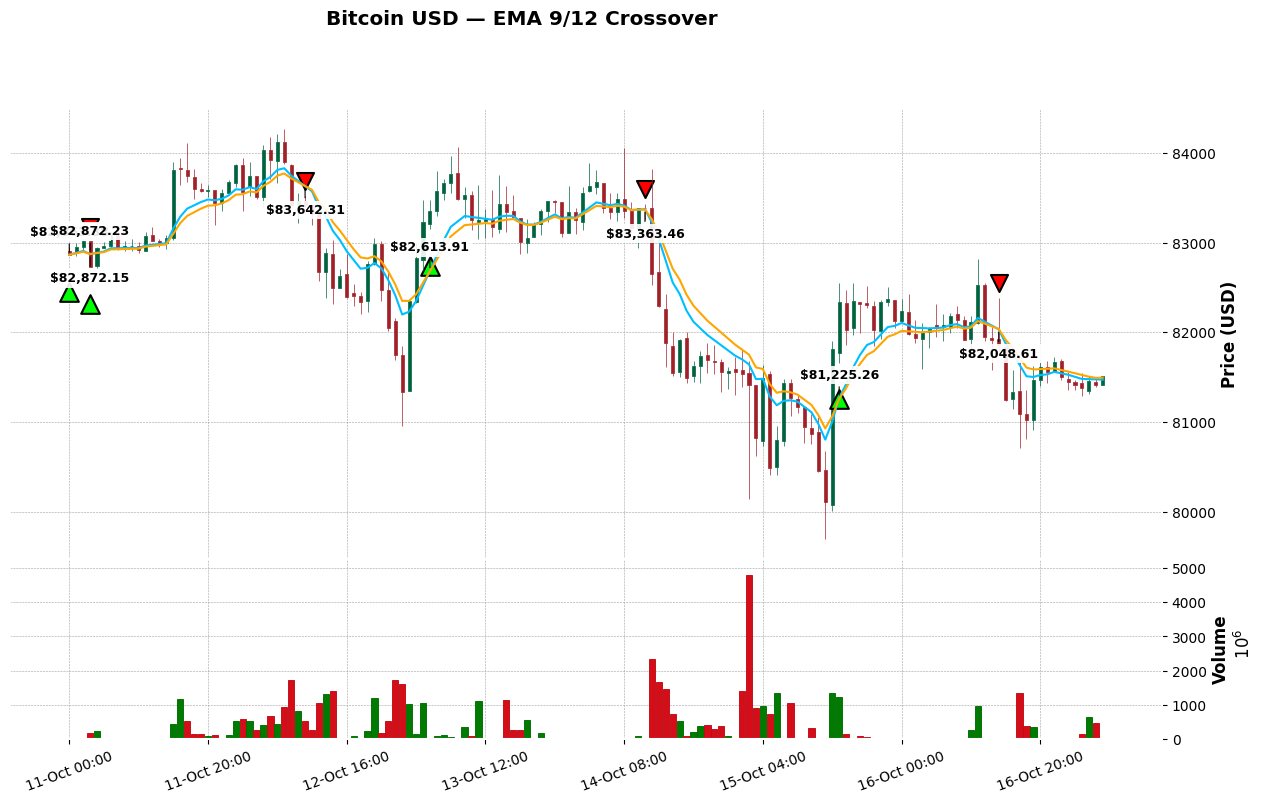


========== EMA 9/12 CROSSOVER DETAILS ==========
            Time      Price  Signal
2026-10-11 00:00 $82,863.38 Bullish
2026-10-11 02:59 $82,872.15 Bearish
2026-10-11 03:02 $82,872.23 Bullish
2026-10-12 09:52 $83,642.31 Bearish
2026-10-13 03:32 $82,613.91 Bullish
2026-10-14 11:03 $83,363.46 Bearish
2026-10-15 14:49 $81,225.26 Bullish
2026-10-16 13:37 $82,048.61 Bearish

Total crossovers: 8
Bullish crossovers: 4
Bearish crossovers: 4


In [11]:
import pandas as pd
import mplfinance as mpf
import matplotlib.pyplot as plt

# Load Bitcoin 7-day, 1-hour data
df = pd.read_csv("Bitcoin_USD_7Day_1Hour_Data.csv")

df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")

for col in ["Open", "High", "Low", "Close", "Volume"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = (
    df.dropna(subset=["Datetime", "Open", "High", "Low", "Close", "Volume"])
      .sort_values("Datetime")
      .drop_duplicates(subset=["Datetime"])
      .set_index("Datetime")
)

# Calculate EMA 9 and EMA 12 on Close prices
df["EMA_9"] = df["Close"].ewm(span=9, adjust=False).mean()
df["EMA_12"] = df["Close"].ewm(span=12, adjust=False).mean()

# Detect bullish and bearish crossovers
difference = df["EMA_9"] - df["EMA_12"]
previous_difference = difference.shift(1)

bullish_idx = df.index[
    (difference > 0) & (previous_difference <= 0)
]

bearish_idx = df.index[
    (difference < 0) & (previous_difference >= 0)
]

# Calculate estimated EMA intersection points
crossovers = []

for idx in bullish_idx.union(bearish_idx).sort_values():
    i = df.index.get_loc(idx)

    if i == 0:
        continue

    prev_diff = difference.iloc[i - 1]
    curr_diff = difference.iloc[i]

    fraction = -prev_diff / (curr_diff - prev_diff)

    prev_ema9 = df["EMA_9"].iloc[i - 1]
    curr_ema9 = df["EMA_9"].iloc[i]

    cross_price = prev_ema9 + fraction * (curr_ema9 - prev_ema9)

    prev_time = df.index[i - 1]
    curr_time = df.index[i]
    cross_time = prev_time + fraction * (curr_time - prev_time)

    signal = "Bullish" if curr_diff > 0 else "Bearish"

    crossovers.append({
        "Time": cross_time,
        "Price": cross_price,
        "Signal": signal
    })

crossovers = pd.DataFrame(
    crossovers,
    columns=["Time", "Price", "Signal"]
)

# Create crossover marker columns
df["Bullish"] = float("nan")
df["Bearish"] = float("nan")

# Place markers slightly away from candle highs and lows
for _, row in crossovers.iterrows():
    nearest_pos = df.index.get_indexer([row["Time"]], method="nearest")[0]
    nearest_idx = df.index[nearest_pos]

    if row["Signal"] == "Bullish":
        df.loc[nearest_idx, "Bullish"] = df.loc[nearest_idx, "Low"] * 0.995
    else:
        df.loc[nearest_idx, "Bearish"] = df.loc[nearest_idx, "High"] * 1.002

# EMA lines and more visible crossover markers
add_plots = [
    mpf.make_addplot(
        df["EMA_9"],
        color="deepskyblue",
        width=1.5
    ),
    mpf.make_addplot(
        df["EMA_12"],
        color="orange",
        width=1.5
    ),
    mpf.make_addplot(
        df["Bullish"],
        type="scatter",
        marker="^",
        markersize=180,
        color="#00FF00",
        edgecolors="black",
        linewidths=1.5
    ),
    mpf.make_addplot(
        df["Bearish"],
        type="scatter",
        marker="v",
        markersize=150,
        color="red",
        edgecolors="black",
        linewidths=1.5
    )
]

# Plot candlestick chart
fig, axes = mpf.plot(
    df,
    type="candle",
    style="charles",
    addplot=add_plots,
    volume=True,
    title="Bitcoin USD — EMA 9/12 Crossover",
    ylabel="Price (USD)",
    ylabel_lower="Volume",
    figsize=(16, 9),
    datetime_format="%d-%b %H:%M",
    xrotation=20,
    returnfig=True,
    warn_too_much_data=1000
)

price_ax = axes[0]

# Display estimated crossover prices
for _, row in crossovers.iterrows():
    nearest_pos = df.index.get_indexer([row["Time"]], method="nearest")[0]

    price_ax.annotate(
        f"${row['Price']:,.2f}",
        xy=(nearest_pos, df["EMA_9"].iloc[nearest_pos]),
        xytext=(
            0,
            14 if row["Signal"] == "Bullish" else -20
        ),
        textcoords="offset points",
        color="black",
        fontsize=9,
        fontweight="bold",
        ha="center",
        arrowprops=dict(
            arrowstyle="-",
            color="black",
            lw=0.8
        ),
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.9,
            pad=2
        )
    )

plt.show()

# Print crossover details
print("\n========== EMA 9/12 CROSSOVER DETAILS ==========")

if crossovers.empty:
    print("No crossover points found in this dataset.")
else:
    print(
        crossovers.to_string(
            index=False,
            formatters={
                "Time": lambda x: x.strftime("%Y-%m-%d %H:%M"),
                "Price": lambda x: f"${x:,.2f}"
            }
        )
    )

    print(f"\nTotal crossovers: {len(crossovers)}")
    print(f"Bullish crossovers: {(crossovers['Signal'] == 'Bullish').sum()}")
    print(f"Bearish crossovers: {(crossovers['Signal'] == 'Bearish').sum()}")


In [10]:
import pandas as pd

df = pd.read_csv("Bitcoin_USD_7Day_1Hour_Data.csv")

df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")
df["Close"] = pd.to_numeric(df["Close"], errors="coerce")

df = (
    df.dropna(subset=["Datetime", "Close"])
      .sort_values("Datetime")
      .drop_duplicates(subset=["Datetime"])
      .reset_index(drop=True)
)

df["EMA_9"] = df["Close"].ewm(span=9, adjust=False).mean()
df["EMA_12"] = df["Close"].ewm(span=12, adjust=False).mean()

df["Difference"] = df["EMA_9"] - df["EMA_12"]
df["Previous_Difference"] = df["Difference"].shift(1)

df["Signal"] = ""

df.loc[
    (df["Difference"] > 0) &
    (df["Previous_Difference"] <= 0),
    "Signal"
] = "Bullish"

df.loc[
    (df["Difference"] < 0) &
    (df["Previous_Difference"] >= 0),
    "Signal"
] = "Bearish"

signals = df[df["Signal"] != ""]

print("Bullish:", (signals["Signal"] == "Bullish").sum())
print("Bearish:", (signals["Signal"] == "Bearish").sum())

display(signals[["Datetime", "Close", "EMA_9", "EMA_12", "Signal"]])

Bullish: 4
Bearish: 4


,Datetime,Close,EMA_9,EMA_12,Signal
1,2026-10-11 01:00:00+00:00,82947.851562,82880.276563,82876.378005,Bullish
3,2026-10-11 03:00:00+00:00,82732.078125,82871.712625,82871.832958,Bearish
4,2026-10-11 04:00:00+00:00,82934.367188,82884.243538,82881.453608,Bullish
34,2026-10-12 10:00:00+00:00,83418.718750,83635.211130,83637.102578,Bearish
52,2026-10-13 04:00:00+00:00,83351.476562,82689.685175,82670.608727,Bullish
84,2026-10-14 12:00:00+00:00,82643.960938,83225.846869,83257.869956,Bearish
111,2026-10-15 15:00:00+00:00,82334.632812,81269.878762,81258.070248,Bullish
134,2026-10-16 14:00:00+00:00,81861.703125,82032.671592,82036.741388,Bearish


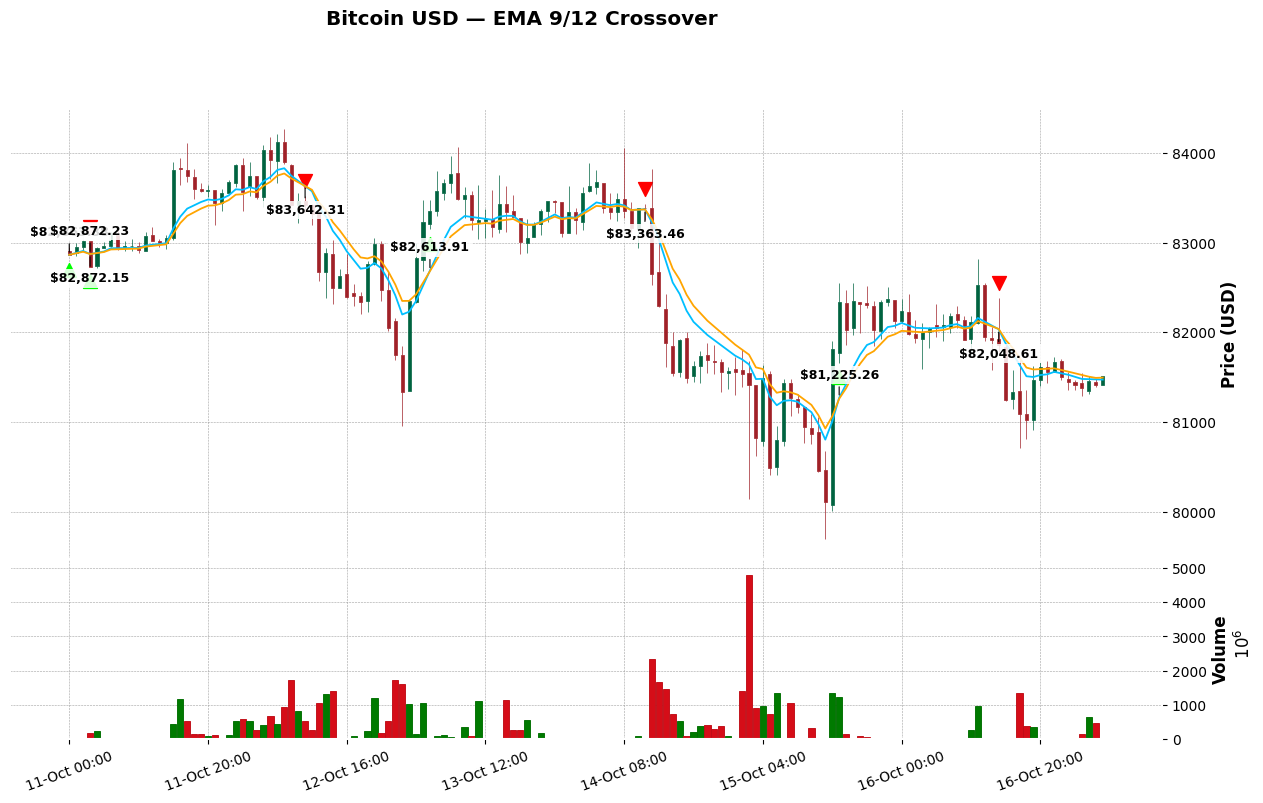


========== EMA 9/12 CROSSOVER DETAILS ==========
            Time      Price  Signal
2026-10-11 00:00 $82,863.38 Bullish
2026-10-11 02:59 $82,872.15 Bearish
2026-10-11 03:02 $82,872.23 Bullish
2026-10-12 09:52 $83,642.31 Bearish
2026-10-13 03:32 $82,613.91 Bullish
2026-10-14 11:03 $83,363.46 Bearish
2026-10-15 14:49 $81,225.26 Bullish
2026-10-16 13:37 $82,048.61 Bearish

Total crossovers: 8
Bullish crossovers: 4
Bearish crossovers: 4


In [12]:
import pandas as pd
import mplfinance as mpf
import matplotlib.pyplot as plt

# Load Bitcoin 7-day, 1-hour data
df = pd.read_csv("Bitcoin_USD_7Day_1Hour_Data.csv")

df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")

for col in ["Open", "High", "Low", "Close", "Volume"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = (
    df.dropna(subset=["Datetime", "Open", "High", "Low", "Close", "Volume"])
      .sort_values("Datetime")
      .drop_duplicates(subset=["Datetime"])
      .set_index("Datetime")
)

# Calculate EMA 9 and EMA 12 on Close prices
df["EMA_9"] = df["Close"].ewm(span=9, adjust=False).mean()
df["EMA_12"] = df["Close"].ewm(span=12, adjust=False).mean()

# Detect bullish and bearish crossovers
difference = df["EMA_9"] - df["EMA_12"]
previous_difference = difference.shift(1)

bullish_idx = df.index[
    (difference > 0) & (previous_difference <= 0)
]

bearish_idx = df.index[
    (difference < 0) & (previous_difference >= 0)
]

# Calculate estimated EMA intersection points
crossovers = []

for idx in bullish_idx.union(bearish_idx).sort_values():
    i = df.index.get_loc(idx)

    if i == 0:
        continue

    prev_diff = difference.iloc[i - 1]
    curr_diff = difference.iloc[i]

    fraction = -prev_diff / (curr_diff - prev_diff)

    prev_ema9 = df["EMA_9"].iloc[i - 1]
    curr_ema9 = df["EMA_9"].iloc[i]

    cross_price = prev_ema9 + fraction * (curr_ema9 - prev_ema9)

    prev_time = df.index[i - 1]
    curr_time = df.index[i]
    cross_time = prev_time + fraction * (curr_time - prev_time)

    signal = "Bullish" if curr_diff > 0 else "Bearish"

    crossovers.append({
        "Time": cross_time,
        "Price": cross_price,
        "Signal": signal
    })

crossovers = pd.DataFrame(
    crossovers,
    columns=["Time", "Price", "Signal"]
)

# Create crossover marker columns
df["Bullish"] = float("nan")
df["Bearish"] = float("nan")

# Place markers on the nearest candle
for _, row in crossovers.iterrows():
    nearest_pos = df.index.get_indexer([row["Time"]], method="nearest")[0]
    nearest_idx = df.index[nearest_pos]

    if row["Signal"] == "Bullish":
        df.loc[nearest_idx, "Bullish"] = df.loc[nearest_idx, "Low"] * 0.998
    else:
        df.loc[nearest_idx, "Bearish"] = df.loc[nearest_idx, "High"] * 1.002

# EMA lines and crossover markers
add_plots = [
    mpf.make_addplot(
        df["EMA_9"],
        color="deepskyblue",
        width=1.3
    ),
    mpf.make_addplot(
        df["EMA_12"],
        color="orange",
        width=1.3
    ),
    mpf.make_addplot(
        df["Bullish"],
        type="scatter",
        marker="^",
        markersize=100,
        color="lime"
    ),
    mpf.make_addplot(
        df["Bearish"],
        type="scatter",
        marker="v",
        markersize=100,
        color="red"
    )
]

# Plot candlestick chart
fig, axes = mpf.plot(
    df,
    type="candle",
    style="charles",
    addplot=add_plots,
    volume=True,
    title="Bitcoin USD — EMA 9/12 Crossover",
    ylabel="Price (USD)",
    ylabel_lower="Volume",
    figsize=(16, 9),
    datetime_format="%d-%b %H:%M",
    xrotation=20,
    returnfig=True,
    warn_too_much_data=1000
)

price_ax = axes[0]

# Display crossover prices in BLACK
for _, row in crossovers.iterrows():
    nearest_pos = df.index.get_indexer([row["Time"]], method="nearest")[0]

    price_ax.annotate(
        f"${row['Price']:,.2f}",
        xy=(nearest_pos, df["EMA_9"].iloc[nearest_pos]),
        xytext=(
            0,
            14 if row["Signal"] == "Bullish" else -20
        ),
        textcoords="offset points",
        color="black",
        fontsize=9,
        fontweight="bold",
        ha="center",
        arrowprops=dict(
            arrowstyle="-",
            color="black",
            lw=0.8
        ),
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.85,
            pad=2
        )
    )

plt.show()

# Print crossover details
print("\n========== EMA 9/12 CROSSOVER DETAILS ==========")

if crossovers.empty:
    print("No crossover points found in this dataset.")
else:
    print(
        crossovers.to_string(
            index=False,
            formatters={
                "Time": lambda x: x.strftime("%Y-%m-%d %H:%M"),
                "Price": lambda x: f"${x:,.2f}"
            }
        )
    )

    print(f"\nTotal crossovers: {len(crossovers)}")
    print(f"Bullish crossovers: {(crossovers['Signal'] == 'Bullish').sum()}")
    print(f"Bearish crossovers: {(crossovers['Signal'] == 'Bearish').sum()}")

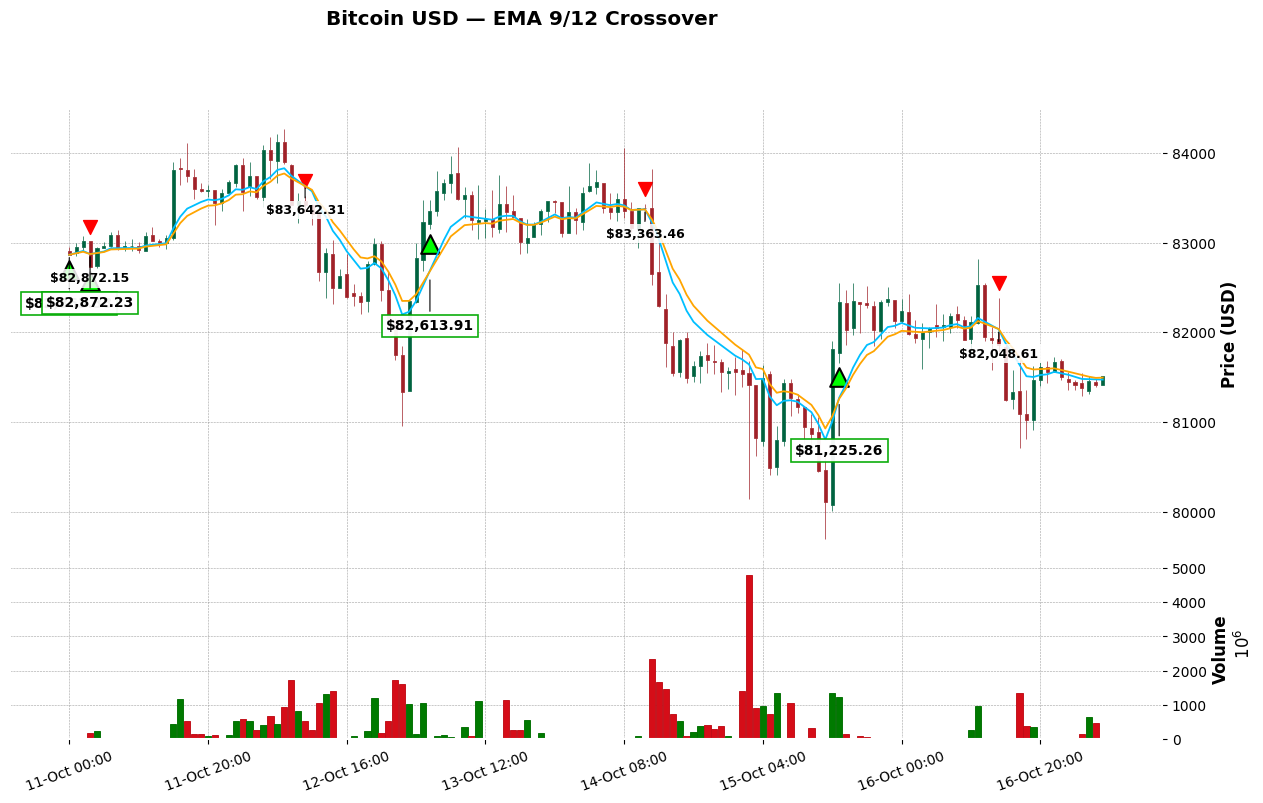


========== EMA 9/12 CROSSOVER DETAILS ==========
            Time      Price  Signal
2026-10-11 00:00 $82,863.38 Bullish
2026-10-11 02:59 $82,872.15 Bearish
2026-10-11 03:02 $82,872.23 Bullish
2026-10-12 09:52 $83,642.31 Bearish
2026-10-13 03:32 $82,613.91 Bullish
2026-10-14 11:03 $83,363.46 Bearish
2026-10-15 14:49 $81,225.26 Bullish
2026-10-16 13:37 $82,048.61 Bearish

Total crossovers: 8
Bullish crossovers: 4
Bearish crossovers: 4


In [13]:
import pandas as pd
import mplfinance as mpf
import matplotlib.pyplot as plt

# Load Bitcoin 7-day, 1-hour data
df = pd.read_csv("Bitcoin_USD_7Day_1Hour_Data.csv")

df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")

for col in ["Open", "High", "Low", "Close", "Volume"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = (
    df.dropna(subset=["Datetime", "Open", "High", "Low", "Close", "Volume"])
      .sort_values("Datetime")
      .drop_duplicates(subset=["Datetime"])
      .set_index("Datetime")
)

# Calculate EMA 9 and EMA 12 on Close prices
df["EMA_9"] = df["Close"].ewm(span=9, adjust=False).mean()
df["EMA_12"] = df["Close"].ewm(span=12, adjust=False).mean()

# Detect bullish and bearish crossovers
difference = df["EMA_9"] - df["EMA_12"]
previous_difference = difference.shift(1)

bullish_idx = df.index[
    (difference > 0) & (previous_difference <= 0)
]

bearish_idx = df.index[
    (difference < 0) & (previous_difference >= 0)
]

# Calculate estimated EMA intersection points
crossovers = []

for idx in bullish_idx.union(bearish_idx).sort_values():
    i = df.index.get_loc(idx)

    if i == 0:
        continue

    prev_diff = difference.iloc[i - 1]
    curr_diff = difference.iloc[i]

    fraction = -prev_diff / (curr_diff - prev_diff)

    prev_ema9 = df["EMA_9"].iloc[i - 1]
    curr_ema9 = df["EMA_9"].iloc[i]

    cross_price = prev_ema9 + fraction * (curr_ema9 - prev_ema9)

    prev_time = df.index[i - 1]
    curr_time = df.index[i]
    cross_time = prev_time + fraction * (curr_time - prev_time)

    signal = "Bullish" if curr_diff > 0 else "Bearish"

    crossovers.append({
        "Time": cross_time,
        "Price": cross_price,
        "Signal": signal
    })

crossovers = pd.DataFrame(
    crossovers,
    columns=["Time", "Price", "Signal"]
)

# Create crossover marker columns
df["Bullish"] = float("nan")
df["Bearish"] = float("nan")

# Place markers on the nearest candle
for _, row in crossovers.iterrows():
    nearest_pos = df.index.get_indexer([row["Time"]], method="nearest")[0]
    nearest_idx = df.index[nearest_pos]

    if row["Signal"] == "Bullish":
        df.loc[nearest_idx, "Bullish"] = df.loc[nearest_idx, "Low"] * 0.998
    else:
        df.loc[nearest_idx, "Bearish"] = df.loc[nearest_idx, "High"] * 1.002

# EMA lines and crossover markers
add_plots = [
    mpf.make_addplot(
        df["EMA_9"],
        color="deepskyblue",
        width=1.3
    ),
    mpf.make_addplot(
        df["EMA_12"],
        color="orange",
        width=1.3
    ),
    # Updated green bullish markers only
    mpf.make_addplot(
        df["Bullish"],
        type="scatter",
        marker="^",
        markersize=180,
        color="#00FF00",
        edgecolors="black",
        linewidths=1.5
    ),
    # Red bearish markers unchanged
    mpf.make_addplot(
        df["Bearish"],
        type="scatter",
        marker="v",
        markersize=100,
        color="red"
    )
]

# Plot candlestick chart
fig, axes = mpf.plot(
    df,
    type="candle",
    style="charles",
    addplot=add_plots,
    volume=True,
    title="Bitcoin USD — EMA 9/12 Crossover",
    ylabel="Price (USD)",
    ylabel_lower="Volume",
    figsize=(16, 9),
    datetime_format="%d-%b %H:%M",
    xrotation=20,
    returnfig=True,
    warn_too_much_data=1000
)

price_ax = axes[0]

# Display crossover prices
for _, row in crossovers.iterrows():
    nearest_pos = df.index.get_indexer([row["Time"]], method="nearest")[0]

    if row["Signal"] == "Bullish":
        # Green crossover price label below the intersection
        price_ax.annotate(
            f"${row['Price']:,.2f}",
            xy=(nearest_pos, row["Price"]),
            xytext=(0, -30),
            textcoords="offset points",
            color="black",
            fontsize=10,
            fontweight="bold",
            ha="center",
            va="top",
            arrowprops=dict(
                arrowstyle="-",
                color="black",
                lw=0.8
            ),
            bbox=dict(
                facecolor="white",
                edgecolor="#00AA00",
                linewidth=1.2,
                alpha=0.95,
                pad=3
            )
        )
    else:
        # Red bearish crossover labels unchanged
        price_ax.annotate(
            f"${row['Price']:,.2f}",
            xy=(nearest_pos, df["EMA_9"].iloc[nearest_pos]),
            xytext=(0, -20),
            textcoords="offset points",
            color="black",
            fontsize=9,
            fontweight="bold",
            ha="center",
            arrowprops=dict(
                arrowstyle="-",
                color="black",
                lw=0.8
            ),
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.85,
                pad=2
            )
        )

plt.show()

# Print crossover details
print("\n========== EMA 9/12 CROSSOVER DETAILS ==========")

if crossovers.empty:
    print("No crossover points found in this dataset.")
else:
    print(
        crossovers.to_string(
            index=False,
            formatters={
                "Time": lambda x: x.strftime("%Y-%m-%d %H:%M"),
                "Price": lambda x: f"${x:,.2f}"
            }
        )
    )

    print(f"\nTotal crossovers: {len(crossovers)}")
    print(f"Bullish crossovers: {(crossovers['Signal'] == 'Bullish').sum()}")
    print(f"Bearish crossovers: {(crossovers['Signal'] == 'Bearish').sum()}")


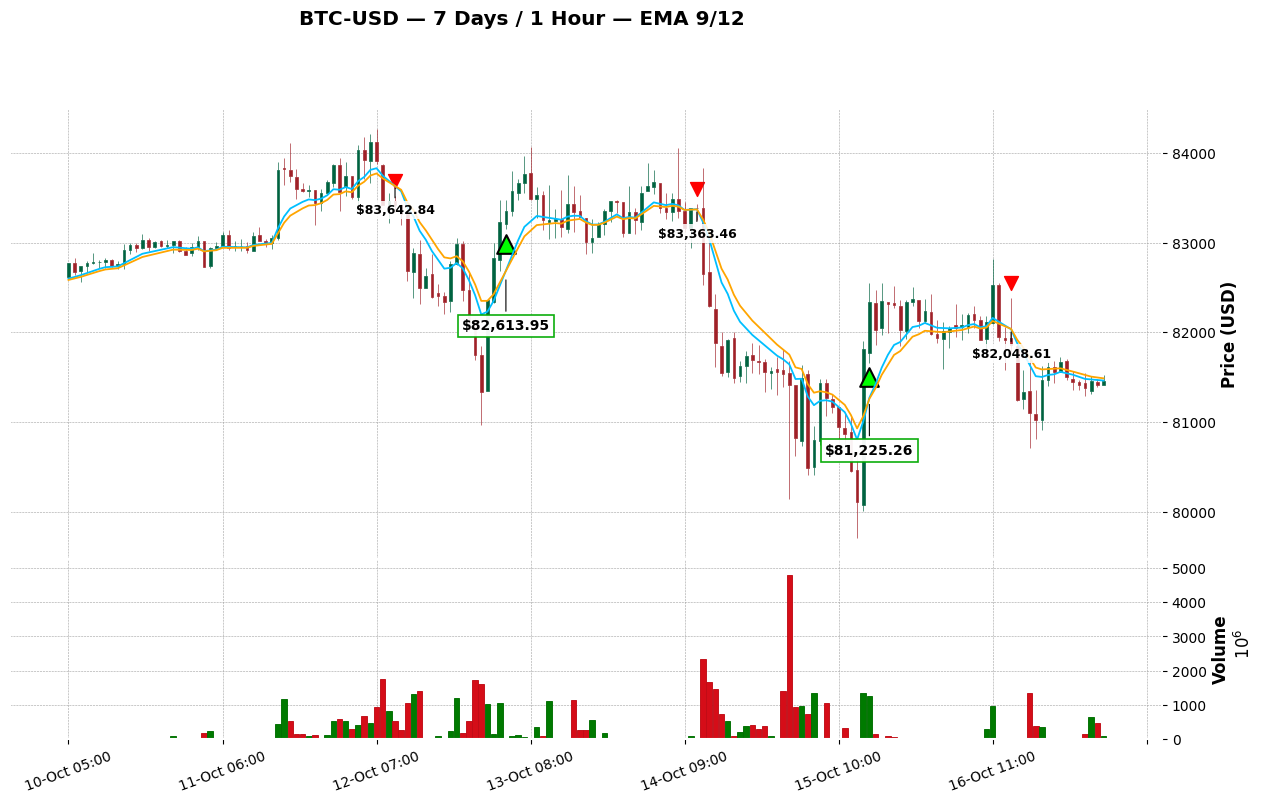


========== BTC-USD EMA CROSSOVERS — LAST 7 DAYS ==========
            Time      Price  Signal
2026-10-12 09:51 $83,642.84 Bearish
2026-10-13 03:32 $82,613.95 Bullish
2026-10-14 11:03 $83,363.46 Bearish
2026-10-15 14:49 $81,225.26 Bullish
2026-10-16 13:37 $82,048.61 Bearish

Total crossovers: 5
Bullish crossovers: 2
Bearish crossovers: 3


In [14]:
import pandas as pd
import yfinance as yf
import mplfinance as mpf
import matplotlib.pyplot as plt

ticker = "BTC-USD"

# Download historical hourly data for EMA initialization
df = yf.download(
    ticker,
    period="60d",
    interval="1h",
    auto_adjust=False,
    progress=False
)

if df.empty:
    raise ValueError("No BTC-USD data received from Yahoo Finance.")

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df[["Open", "High", "Low", "Close", "Volume"]].copy()
df = df.apply(pd.to_numeric, errors="coerce").dropna()
df = df[~df.index.duplicated(keep="last")].sort_index()

# Calculate EMAs before selecting the display period
df["EMA_9"] = df["Close"].ewm(span=9, adjust=False).mean()
df["EMA_12"] = df["Close"].ewm(span=12, adjust=False).mean()

# Detect crossovers
difference = df["EMA_9"] - df["EMA_12"]
previous_difference = difference.shift(1)

bullish_idx = df.index[
    (difference > 0) & (previous_difference <= 0)
]

bearish_idx = df.index[
    (difference < 0) & (previous_difference >= 0)
]

crossovers = []

for idx in bullish_idx.union(bearish_idx).sort_values():
    i = df.index.get_loc(idx)

    if i == 0:
        continue

    prev_diff = difference.iloc[i - 1]
    curr_diff = difference.iloc[i]

    fraction = -prev_diff / (curr_diff - prev_diff)

    prev_ema9 = df["EMA_9"].iloc[i - 1]
    curr_ema9 = df["EMA_9"].iloc[i]

    cross_price = prev_ema9 + fraction * (curr_ema9 - prev_ema9)

    prev_time = df.index[i - 1]
    curr_time = df.index[i]
    cross_time = prev_time + fraction * (curr_time - prev_time)

    crossovers.append({
        "Time": cross_time,
        "Price": cross_price,
        "Signal": "Bullish" if curr_diff > 0 else "Bearish"
    })

crossovers = pd.DataFrame(
    crossovers,
    columns=["Time", "Price", "Signal"]
)

# Select only the latest 7 days for plotting
cutoff = df.index.max() - pd.Timedelta(days=7)
plot_df = df.loc[df.index >= cutoff].copy()

if not crossovers.empty:
    crossovers = crossovers[
        (crossovers["Time"] >= plot_df.index.min()) &
        (crossovers["Time"] <= plot_df.index.max())
    ].copy()

plot_df["Bullish"] = float("nan")
plot_df["Bearish"] = float("nan")

for _, row in crossovers.iterrows():
    pos = plot_df.index.get_indexer([row["Time"]], method="nearest")[0]
    candle_time = plot_df.index[pos]

    if row["Signal"] == "Bullish":
        plot_df.loc[candle_time, "Bullish"] = plot_df.loc[candle_time, "Low"] * 0.998
    else:
        plot_df.loc[candle_time, "Bearish"] = plot_df.loc[candle_time, "High"] * 1.002

add_plots = [
    mpf.make_addplot(plot_df["EMA_9"], color="deepskyblue", width=1.3),
    mpf.make_addplot(plot_df["EMA_12"], color="orange", width=1.3),
    mpf.make_addplot(
        plot_df["Bullish"],
        type="scatter",
        marker="^",
        markersize=180,
        color="#00FF00",
        edgecolors="black",
        linewidths=1.5
    ),
    mpf.make_addplot(
        plot_df["Bearish"],
        type="scatter",
        marker="v",
        markersize=100,
        color="red"
    )
]

fig, axes = mpf.plot(
    plot_df,
    type="candle",
    style="charles",
    addplot=add_plots,
    volume=True,
    title="BTC-USD — 7 Days / 1 Hour — EMA 9/12",
    ylabel="Price (USD)",
    ylabel_lower="Volume",
    figsize=(16, 9),
    datetime_format="%d-%b %H:%M",
    xrotation=20,
    returnfig=True,
    warn_too_much_data=1000
)

price_ax = axes[0]

for _, row in crossovers.iterrows():
    pos = plot_df.index.get_indexer([row["Time"]], method="nearest")[0]

    if row["Signal"] == "Bullish":
        price_ax.annotate(
            f"${row['Price']:,.2f}",
            xy=(pos, row["Price"]),
            xytext=(0, -30),
            textcoords="offset points",
            color="black",
            fontsize=10,
            fontweight="bold",
            ha="center",
            va="top",
            arrowprops=dict(arrowstyle="-", color="black", lw=0.8),
            bbox=dict(
                facecolor="white",
                edgecolor="#00AA00",
                linewidth=1.2,
                alpha=0.95,
                pad=3
            )
        )
    else:
        price_ax.annotate(
            f"${row['Price']:,.2f}",
            xy=(pos, plot_df["EMA_9"].iloc[pos]),
            xytext=(0, -20),
            textcoords="offset points",
            color="black",
            fontsize=9,
            fontweight="bold",
            ha="center",
            arrowprops=dict(arrowstyle="-", color="black", lw=0.8),
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.85,
                pad=2
            )
        )

plt.show()

print("\n========== BTC-USD EMA CROSSOVERS — LAST 7 DAYS ==========")

if crossovers.empty:
    print("No crossover points found in this period.")
else:
    print(
        crossovers.to_string(
            index=False,
            formatters={
                "Time": lambda x: x.strftime("%Y-%m-%d %H:%M"),
                "Price": lambda x: f"${x:,.2f}"
            }
        )
    )

    print(f"\nTotal crossovers: {len(crossovers)}")
    print(f"Bullish crossovers: {(crossovers['Signal'] == 'Bullish').sum()}")
    print(f"Bearish crossovers: {(crossovers['Signal'] == 'Bearish').sum()}")
